In [2]:
from pathlib import Path
from aare import RawFile
import numpy as np
import matplotlib.pyplot as plt
import os

#base = Path('/data_pool/data/pollux202509/osa_scan_20250911')
#base = Path('/data_pool/data/pollux202509/osa_scan_simone_20250912')
#base = Path('/data_pool/data/pollux202509/osa_scan_simone2_20250912')
#base = Path('/data_pool/data/pollux202509/osa_scan_alone_20250914')
#base = Path('/data_pool/data/pollux202509/osa_scan_alone2_20250914')
#base = Path('/data_pool/data/pollux202509/osa_scan_alone3_20250914')
base = Path('/data_pool/data/pollux202610/osa_scan_780eV_diffused_beam')
files = os.listdir(base)
data_files = [f for f in files if f.endswith('.json')]
#pedestal_file = 'pedestal_master_91.json' # alone
#pedestal_file = 'pedestal_master_348.json' # alone2
#pedestal_file = 'pedestal_master_608.json'# alone3
pedestal_file = 'dark_master_0.json'
#pedestal_file2 = 'dark_master_405.json'
data_files.remove(pedestal_file)
#data_files.remove(pedestal_file2)
#data_files.remove('pedestal_master_0.json')

In [3]:
def extract_xy(filename):
    splitting = filename.split('_')
    x = splitting[1]
    y = splitting[3]
    return (int(x),int(y))

In [4]:
sorted_files = sorted(data_files, key=extract_xy)
#print(sorted_files)

In [5]:
len(data_files)

625

In [10]:
sorted_files

['x_-1000_y_-1000_master_1.json',
 'x_-1000_y_-920_master_26.json',
 'x_-1000_y_-840_master_51.json',
 'x_-1000_y_-760_master_76.json',
 'x_-1000_y_-680_master_101.json',
 'x_-1000_y_-600_master_126.json',
 'x_-1000_y_-520_master_151.json',
 'x_-1000_y_-440_master_176.json',
 'x_-1000_y_-360_master_201.json',
 'x_-1000_y_-280_master_226.json',
 'x_-1000_y_-200_master_251.json',
 'x_-1000_y_-120_master_276.json',
 'x_-1000_y_-40_master_301.json',
 'x_-1000_y_40_master_326.json',
 'x_-1000_y_120_master_351.json',
 'x_-1000_y_200_master_376.json',
 'x_-1000_y_280_master_401.json',
 'x_-1000_y_360_master_426.json',
 'x_-1000_y_440_master_451.json',
 'x_-1000_y_520_master_476.json',
 'x_-1000_y_600_master_501.json',
 'x_-1000_y_680_master_526.json',
 'x_-1000_y_760_master_551.json',
 'x_-1000_y_840_master_576.json',
 'x_-1000_y_920_master_601.json',
 'x_-920_y_-1000_master_2.json',
 'x_-920_y_-920_master_27.json',
 'x_-920_y_-840_master_52.json',
 'x_-920_y_-760_master_77.json',
 'x_-920_y_

In [6]:
f = RawFile(base / data_files[0])
R = 1
headers, data = f.read()
del headers
# data has an ROI
len_y = data.shape[2]
len_x = data.shape[1]
# print(data.shape)
del data

In [7]:
pedestal = np.empty((len_x, len_y), dtype=np.float16)
with RawFile(base / pedestal_file, chunk_size=100000) as f:
            for header, data in f:
                del header
                pedestal = np.mean(data, axis=0)
                std = np.std(data, axis=0)
                del data

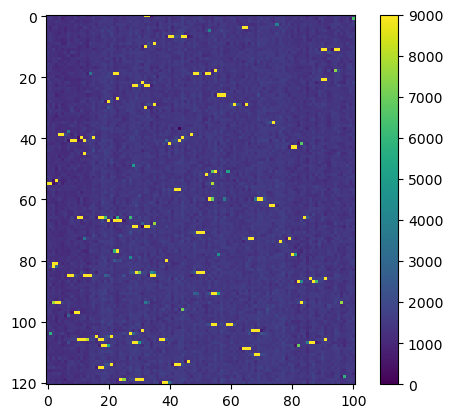

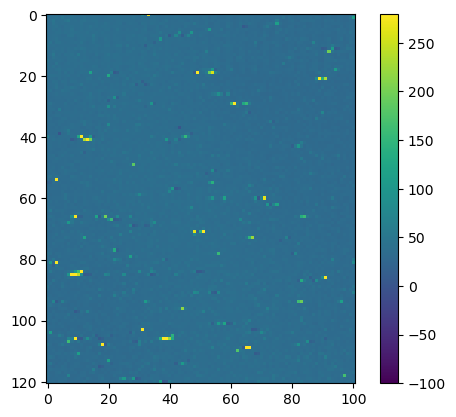

In [8]:
mean_ped = np.mean(pedestal)
std_ped = np.std(pedestal)

mean_noise = np.mean(std)
std_noise = np.std(std)

# plot_pedestal = 

plt.imshow(pedestal, vmin=0, vmax = 9000)
plt.colorbar()
plt.show()
plt.imshow(std, vmin=-100, vmax = 280)
plt.colorbar()


In [69]:
mean_noise + std_noise

np.float64(279.1540569449562)

/tmp/ipykernel_1256911/2265860076.py:9: RuntimeWarning: divide by zero encountered in log
  im = ax.imshow(np.log(accumulate), cmap='viridis')  # 'viridis' is a good default colormap
/tmp/ipykernel_1256911/2265860076.py:9: RuntimeWarning: invalid value encountered in log
  im = ax.imshow(np.log(accumulate), cmap='viridis')  # 'viridis' is a good default colormap


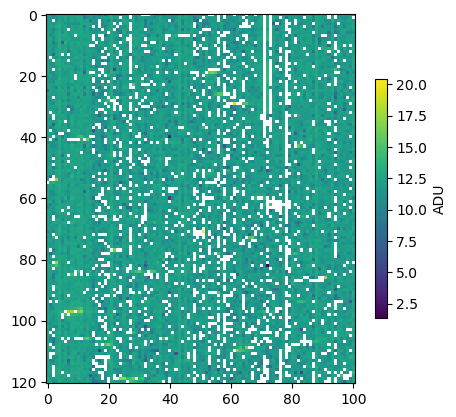

In [24]:
fig, ax = plt.subplots()
accumulate = np.zeros((len_x, len_y))
for k in range(len(sorted_files[0])):
    f = RawFile(base / sorted_files[k])
    #R = 10
    headers, data = f.read()
    del headers
    accumulate += np.sum(data-pedestal, axis=0)
im = ax.imshow(np.log(accumulate), cmap='viridis')  # 'viridis' is a good default colormap
#im.set_clim(-100, 10000)  # Adjust color limits for better contrast
cbar = plt.colorbar(im, ax=ax, fraction=0.024, pad=0.04)
cbar.set_label('ADU')  # Add label to colorbar for clarity
#print(np.argwhere(data[0] > 0), data[0,8,13], np.mean(data[:,8,13]))
del data

In [9]:
# Plot the integrated signal of our ROI over all OSA positions
picture_s = np.zeros((len_x, len_y), dtype=np.float32)
ix = 0
iy = -1
osa_step_y = 16
for filename in sorted_files:
    if iy == osa_step_y-1:
        ix += 1
        iy = -1
    iy += 1
    filepath = os.path.join(base, filename)
    with RawFile(filepath, chunk_size=1000) as f:
            for header, data in f:
                del header
                data = np.sum(data, axis=0) - pedestal[chosen_pixel]
                picture_s += data
                del data

NameError: name 'chosen_pixel' is not defined

In [ ]:
fig, ax = plt.subplots()
im = ax.imshow(picture_s, cmap='viridis')  # 'viridis' is a good default colormap
im.set_clim(-100, 10000)  # Adjust color limits for better contrast
cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
cbar.set_label('ADU')  # Add label to colorbar for clarity
ax.set_xlabel('pixel')
ax.set_ylabel('pixel')
ax.set_title('Integration over all OSA positions')

In [ ]:
# Plot the integrated value of one pixel for all OSA positions
#chosen_pixel = (int(len_x/2), int(len_y/2))
chosen_pixel = (15, 15)
osa_step_x = 16
osa_step_y = 16
osax_range = np.linspace(-1200, -800, osa_step_x, dtype=np.int16)
osay_range = np.linspace(11640, 12040, osa_step_y, dtype=np.uint16)
picture = np.empty((osa_step_x, osa_step_y), dtype=np.float32)
ix = 0
iy = -1
for filename in sorted_files:
    if iy == osa_step_y-1:
        ix += 1
        iy = -1
    iy += 1
    filepath = os.path.join(base, filename)
    with RawFile(filepath, chunk_size=1000) as f:
            for header, data in f:
                del header
                data = data[:,chosen_pixel].astype(dtype=np.float16, copy=False) - pedestal[chosen_pixel]
                picture[ix, iy]= np.sum(data)
                del data

In [ ]:
adc_mask = 0b11111111111111
gain_mask = 0b1100000000000000
print(adc_mask)
print(gain_mask)

In [10]:
%%time
# Plot for every OSA position the sum over all ROI pixels and all frames
#osa_step_x = 16 # alone
#osa_step_y = 16 # alone
#osax_range = np.linspace(-1051,-676, osa_step_x, dtype=np.int16) # alone
#osay_range = np.linspace(11640, 12015, osa_step_y, dtype=np.uint16) # alone
osa_step_x = 25 # alone2
osa_step_y = 25 # alone2
osax_range = np.linspace(-1000,1000, osa_step_x, dtype=np.int16) # alone2
osay_range = np.linspace(-1000,1000, osa_step_y, dtype=np.int16) # alone2
picture = np.empty((osa_step_x, osa_step_y), dtype=np.float32)
coordinates =  np.zeros((osa_step_x, osa_step_y, 2), dtype=np.float32)
ix = 0
iy = -1
pedestal_mask = (pedestal > (mean_ped + std_ped))
noise_mask = (std > (mean_noise + std_noise))
mask = pedestal_mask | noise_mask
for filename in sorted_files:
    if iy == osa_step_y-1:
        ix += 1
        iy = -1
    iy += 1
    filepath = os.path.join(base, filename)
    coordinates[ix, iy] = extract_xy(filename)
    with RawFile(filepath, chunk_size=1000) as f:
            for header, data in f:
                del header
                corrected_data = data-pedestal
                corrected_data[:,mask] = 0
                picture[ix, iy]= np.sum(corrected_data)
                # picture[ix, iy]= np.sum((data & gain_mask))
                del data

CPU times: user 15.1 s, sys: 31 s, total: 46.1 s
Wall time: 1min 31s


In [ ]:
print('axis0 coordinates "X"')
print(coordinates[:,0,0])
print('axis1 coordinates "Y"')
print(coordinates[0,:,1])

In [ ]:
print('Coordinate of max intensity:')
print(coordinates[np.unravel_index(np.argmax(picture), picture.shape)])
print('Index of the max intensity:')
print(np.unravel_index(np.argmax(picture), picture.shape))

In [11]:
# For common extent we need extentfloats (left, right, bottom, top)
# left to right is axis1 and bottom to top is axis0 usually (0,0) top left, with origin 'lower' at bottom left
left = coordinates[0,0,1]
right = coordinates[0,-1,1]
bottom = coordinates[-1,0,0]
top  = coordinates[0,0,0]

print(f'extent would be: left={left}, right={right}, bottom={bottom}, top={top}')

extent would be: left=-1000.0, right=920.0, bottom=920.0, top=-1000.0


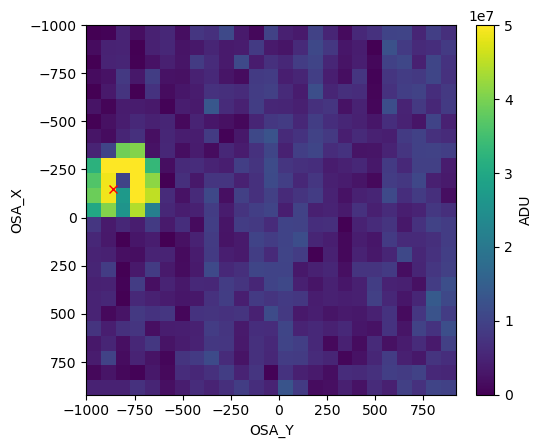

In [12]:
fig, ax = plt.subplots()
# im = ax.imshow(picture, extent=[osay_range[0], osay_range[-1], osax_range[-1], osax_range[0]], cmap='viridis')  # 'viridis' is a good default colormap
# im = ax.imshow(picture, origin='lower', cmap='viridis')
im = ax.imshow(picture, extent=[left, right, bottom, top], cmap='viridis')
# im = ax.imshow(picture, extent=[osay_range[0], osay_range[-1], osax_range[0], osax_range[-1]], cmap='viridis')  # 'viridis' is a good default colormap
im.set_clim(0, 5e7)
cbar = plt.colorbar(im, ax=ax, fraction=0.04, pad=0.04)
cbar.set_label('ADU')  # Add label to colorbar for clarity
#ax.set_title(chosen_pixel)
ax.set_xlabel('OSA_Y')
ax.set_ylabel('OSA_X')
# plt.plot(-100,240, marker='x', color='r')
#ax.set_xticklabels(osax_range)
#ax.set_yticklabels(osay_range)
#ax.set_xlim(-150, -50)
#ax.set_ylim(200,280)
plt.plot(-860,-150, marker='x', color='r')

In [90]:
fname = 'x_-840_y_-200_master_253.json'
filepath = os.path.join(base, fname)
accumulated = np.zeros((len_x, len_y))
with RawFile(filepath, chunk_size=1000) as f:
        for header, data in f:
            del header
            accumulated += np.sum(data-pedestal, axis=0)
            # picture[ix, iy]= np.sum((data & gain_mask))
            del data

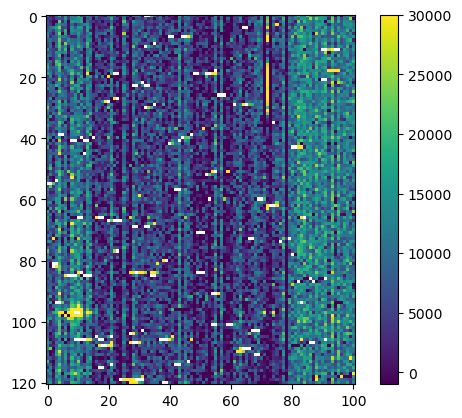

In [94]:
plt_image = accumulated.copy()
plt_image[mask] = np.nan
im = plt.imshow(plt_image)
plt.colorbar(im)
plt.clim(-1000,30000)

In [62]:
mask.sum()

np.int64(154)